# Pneumonia Detection from Chest X-rays (Transfer Learning + Grad-CAM)

**Goal:** classify chest X-rays as NORMAL or PNEUMONIA with a DenseNet121 transfer-learning model, evaluated with screening-appropriate metrics (recall, precision, ROC-AUC), with Grad-CAM explanations.

> Screening demo for learning purposes. **Not a diagnostic tool.**

**What changed from the first version (73% test accuracy, Normal recall 0.29, heavy overfitting):**
1. Transfer learning (DenseNet121, ImageNet weights) instead of a small CNN from scratch
2. Augmentation applied *during training* (the first version only applied it to validation data)
3. Class weights to handle the Pneumonia/Normal imbalance
4. A proper validation set (stratified split of train+val; the original val folder has only 16 images)
5. Metrics: recall, precision, F1, ROC-AUC, confusion matrix; decision threshold tuned on validation data only
6. Grad-CAM heatmaps and error analysis
7. MLflow experiment tracking to compare runs (baseline CNN vs DenseNet121, with/without class weights)

## 1. Setup

In [11]:
import os, random, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, precision_recall_curve)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

IMG_SIZE = 224
BATCH = 32
# Kaggle "Chest X-Ray Images (Pneumonia)" folder with train/ val/ test/ subfolders
DATA_DIR = '/content/drive/MyDrive/Pneumonia_Project/chest_xray'
print(tf.__version__, tf.config.list_physical_devices('GPU'))

2.21.0 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Load file paths and labels
Label convention: **1 = PNEUMONIA (positive class)**, 0 = NORMAL. Using pneumonia as the positive class makes recall mean "share of pneumonia cases caught".

In [13]:
def list_images(split):
    rows = []
    for cls, label in [('NORMAL', 0), ('PNEUMONIA', 1)]:
        folder = os.path.join(DATA_DIR, split, cls)
        for f in os.listdir(folder):
            if f.lower().endswith(('.jpeg', '.jpg', '.png')):
                rows.append((os.path.join(folder, f), label))
    return pd.DataFrame(rows, columns=['path', 'label'])

# Load directly from the train folder since there is no separate val folder
df_train_full = list_images('train')
df_test = list_images('test')          # official test set, kept untouched until the end

print('train:', len(df_train_full), '| test:', len(df_test))
print(df_train_full.label.value_counts().rename({0: 'NORMAL', 1: 'PNEUMONIA'}))

train: 5233 | test: 624
label
PNEUMONIA    3883
NORMAL       1350
Name: count, dtype: int64


## 3. Stratified train / validation split
The original `val` folder has only 16 images, which makes validation metrics very noisy. I merge train+val and take a stratified 15% validation split. The official `test` folder is only used for the final evaluation.

4448 785 624
class weights: {0: np.float64(1.93897122929381), 1: np.float64(0.6737352317479551)}


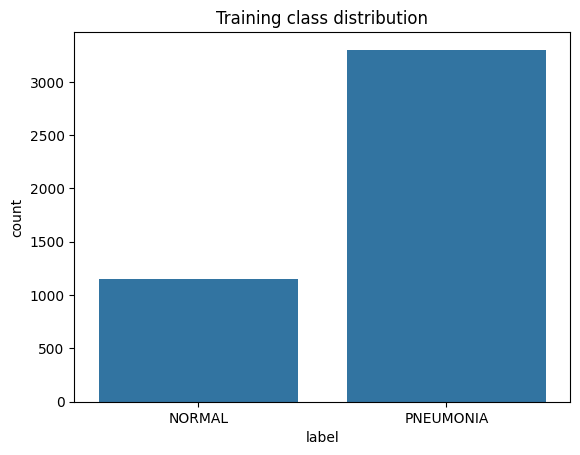

In [14]:
df_train, df_val = train_test_split(
    df_train_full, test_size=0.15, stratify=df_train_full.label, random_state=SEED)
print(len(df_train), len(df_val), len(df_test))

weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=df_train.label)
class_weight = {0: weights[0], 1: weights[1]}
print('class weights:', class_weight)

sns.countplot(x=df_train.label.map({0: 'NORMAL', 1: 'PNEUMONIA'}))
plt.title('Training class distribution'); plt.show()

## 4. Input pipeline (tf.data)
X-rays are grayscale; DenseNet expects 3 channels, so the single channel is replicated on load.

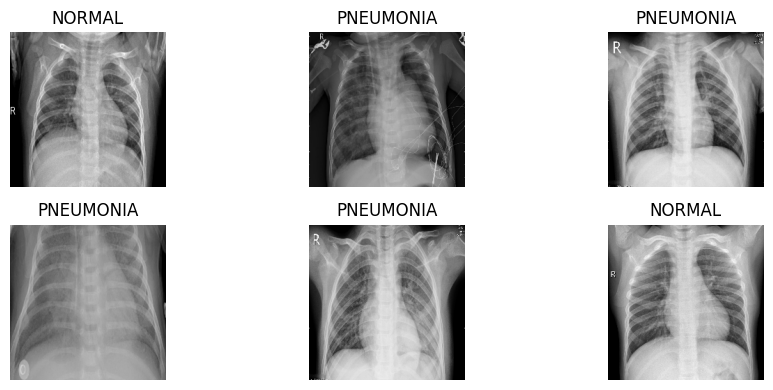

In [15]:
# DenseNet ImageNet preprocessing ("torch" mode), written with plain layers so the saved model
# loads anywhere without custom objects.
MEAN = np.array([0.485, 0.456, 0.406], dtype='float32')
STD  = np.array([0.229, 0.224, 0.225], dtype='float32')
def prep(x):                      # used only by Grad-CAM; the model has the same steps built in
    return (tf.cast(x, tf.float32) / 255.0 - MEAN) / STD

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, tf.cast(label, tf.float32)

def make_ds(df, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((df.path.values, df.label.values))
    if shuffle:
        ds = ds.shuffle(len(df), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(df_train, shuffle=True)
val_ds   = make_ds(df_val)
test_ds  = make_ds(df_test)

# quick look at a few samples
imgs, labs = next(iter(train_ds))
plt.figure(figsize=(10, 4))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(imgs[i].numpy().astype('uint8'))
    plt.title('PNEUMONIA' if labs[i] == 1 else 'NORMAL'); plt.axis('off')
plt.tight_layout(); plt.show()

## 5. Model: DenseNet121 + augmentation (active only in training)
The augmentation layers are part of the model, so Keras applies them automatically during `fit` and switches them off for `predict`/`evaluate`. The model is built as one flat functional graph so Grad-CAM can reach the last convolutional layer.

In [16]:
def build_model():
    base = keras.applications.DenseNet121(
        include_top=False, weights='imagenet', input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.RandomFlip('horizontal')(inputs)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.1)(x)
    x = layers.RandomContrast(0.1)(x)
    x = layers.Rescaling(1.0 / 255)(x)
    x = layers.Normalization(mean=MEAN.tolist(), variance=(STD ** 2).tolist())(x)
    x = base(x, training=False)          # keep BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    return keras.Model(inputs, outputs), base

model, base = build_model()
metrics = [keras.metrics.AUC(name='auc'),
           keras.metrics.Recall(name='recall'),
           keras.metrics.Precision(name='precision')]
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='binary_crossentropy', metrics=metrics)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization_1 (Normalization) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,038,529 (26.85 MB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

## 6. Training, phase 1: train the new head with the base frozen

In [17]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=3,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_auc', mode='max', factor=0.3,
                                      patience=1, min_lr=1e-6, verbose=1),
]
h1 = model.fit(train_ds, validation_data=val_ds, epochs=8,
               class_weight=class_weight, callbacks=callbacks)

Epoch 1/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 63s 334ms/step - auc: 0.8144 - loss: 0.5266 - precision: 0.8925 - recall: 0.7246 - val_auc: 0.9748 - val_loss: 0.3938 - val_precision: 0.9934 - val_recall: 0.7801 - learning_rate: 0.0010
Epoch 2/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 47s 341ms/step - auc: 0.9372 - loss: 0.3279 - precision: 0.9510 - recall: 0.8649 - val_auc: 0.9813 - val_loss: 0.2242 - val_precision: 0.9850 - val_recall: 0.9038 - learning_rate: 0.0010
Epoch 3/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 82s 342ms/step - auc: 0.9551 - loss: 0.2781 - precision: 0.9602 - recall: 0.8840 - val_auc: 0.9846 - val_loss: 0.1726 - val_precision: 0.9804 - val_recall: 0.9433 - learning_rate: 0.0010
Epoch 4/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 45s 322ms/step - auc: 0.9608 - loss: 0.2592 - precision: 0.9615 - recall: 0.8937 - val_auc: 0.9860 - val_loss: 0.2270 - val_precision: 0.9903 - val_recall: 0.8797 - learning_rate: 0.0010
Epoch 5/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 45s 323ms/step - auc: 0.9641 - loss: 0.2454 - precision: 

## 7. Training, phase 2: fine-tune the top of the backbone
Unfreeze the last ~40 layers (BatchNorm layers stay frozen) and train with a much smaller learning rate.

In [18]:
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss='binary_crossentropy', metrics=metrics)
h2 = model.fit(train_ds, validation_data=val_ds, epochs=8,
               class_weight=class_weight, callbacks=callbacks)

Epoch 1/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 65s 355ms/step - auc: 0.9760 - loss: 0.2086 - precision: 0.9739 - recall: 0.9112 - val_auc: 0.9877 - val_loss: 0.1727 - val_precision: 0.9835 - val_recall: 0.9192 - learning_rate: 1.0000e-05
Epoch 2/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 74s 306ms/step - auc: 0.9725 - loss: 0.2109 - precision: 0.9707 - recall: 0.9121 - val_auc: 0.9886 - val_loss: 0.1696 - val_precision: 0.9835 - val_recall: 0.9227 - learning_rate: 1.0000e-05
Epoch 3/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 43s 306ms/step - auc: 0.9801 - loss: 0.1821 - precision: 0.9764 - recall: 0.9264 - val_auc: 0.9896 - val_loss: 0.1475 - val_precision: 0.9839 - val_recall: 0.9450 - learning_rate: 1.0000e-05
Epoch 4/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 43s 312ms/step - auc: 0.9788 - loss: 0.1857 - precision: 0.9757 - recall: 0.9258 - val_auc: 0.9902 - val_loss: 0.1877 - val_precision: 0.9868 - val_recall: 0.9021 - learning_rate: 1.0000e-05
Epoch 5/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 43s 310ms/step - auc: 0.9829 - loss: 0.16

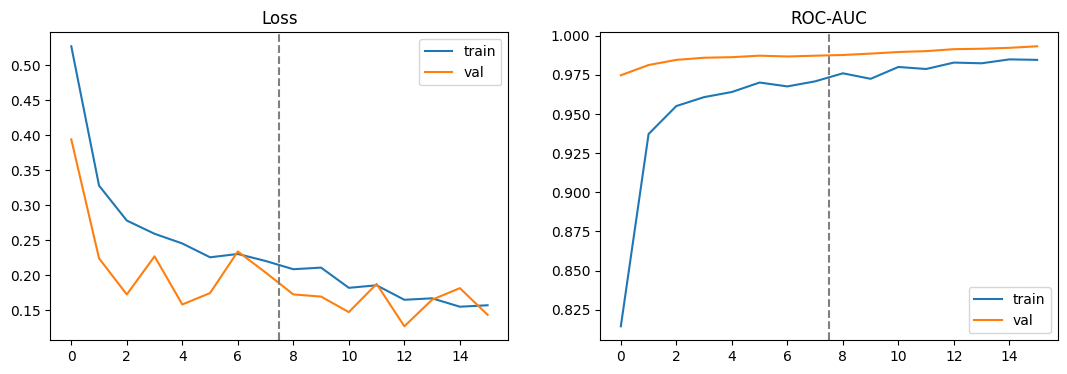

In [19]:
hist = {k: h1.history[k] + h2.history[k] for k in h1.history}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist['loss'], label='train'); ax[0].plot(hist['val_loss'], label='val')
ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(hist['auc'], label='train'); ax[1].plot(hist['val_auc'], label='val')
ax[1].set_title('ROC-AUC'); ax[1].legend()
for a in ax: a.axvline(len(h1.history['loss']) - 0.5, ls='--', c='gray')
plt.show()

## 8. Choose the decision threshold on the VALIDATION set
For screening, missing a pneumonia case is worse than a false alarm, so I pick the highest-precision threshold that still keeps validation recall at or above 95%. The test set is not used for this choice.

In [20]:
val_prob = model.predict(val_ds).ravel()
val_true = df_val.label.values
prec, rec, thr = precision_recall_curve(val_true, val_prob)
ok = np.where(rec[:-1] >= 0.95)[0]
THRESHOLD = float(thr[ok[np.argmax(prec[:-1][ok])]]) if len(ok) else 0.5
print('Chosen threshold:', round(THRESHOLD, 3))

25/25 ━━━━━━━━━━━━━━━━━━━━ 14s 403ms/step
Chosen threshold: 0.246


## 9. Final evaluation on the official test set

In [21]:
test_prob = model.predict(test_ds).ravel()
test_true = df_test.label.values
names = ['NORMAL', 'PNEUMONIA']

for t in (0.5, THRESHOLD):
    pred = (test_prob >= t).astype(int)
    print(f'===== threshold = {t:.3f} =====')
    print(classification_report(test_true, pred, target_names=names, digits=3))
print('Test ROC-AUC:', round(roc_auc_score(test_true, test_prob), 4))

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 207ms/step
===== threshold = 0.500 =====
              precision    recall  f1-score   support

      NORMAL      0.925     0.735     0.819       234
   PNEUMONIA      0.858     0.964     0.908       390

    accuracy                          0.878       624
   macro avg      0.892     0.850     0.864       624
weighted avg      0.883     0.878     0.875       624

===== threshold = 0.246 =====
              precision    recall  f1-score   support

      NORMAL      0.951     0.581     0.721       234
   PNEUMONIA      0.796     0.982     0.879       390

    accuracy                          0.832       624
   macro avg      0.874     0.782     0.800       624
weighted avg      0.854     0.832     0.820       624

Test ROC-AUC: 0.9586


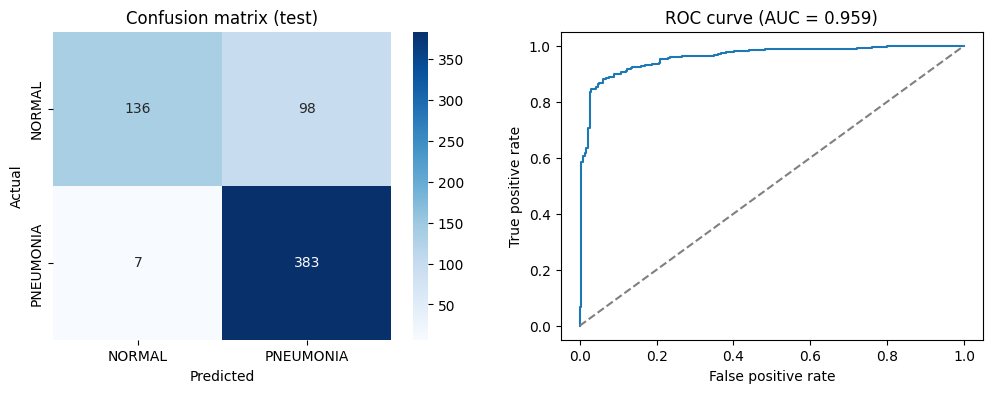

In [22]:
pred = (test_prob >= THRESHOLD).astype(int)
cm = confusion_matrix(test_true, pred)
fpr, tpr, _ = roc_curve(test_true, test_prob)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=names, yticklabels=names, ax=ax[0])
ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('Actual'); ax[0].set_title('Confusion matrix (test)')
ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], '--', c='gray')
ax[1].set_title(f'ROC curve (AUC = {roc_auc_score(test_true, test_prob):.3f})')
ax[1].set_xlabel('False positive rate'); ax[1].set_ylabel('True positive rate')
plt.show()

## 10. Grad-CAM: where is the model looking?
Heatmaps help check that the model focuses on lung regions and not on artifacts such as markers or borders.

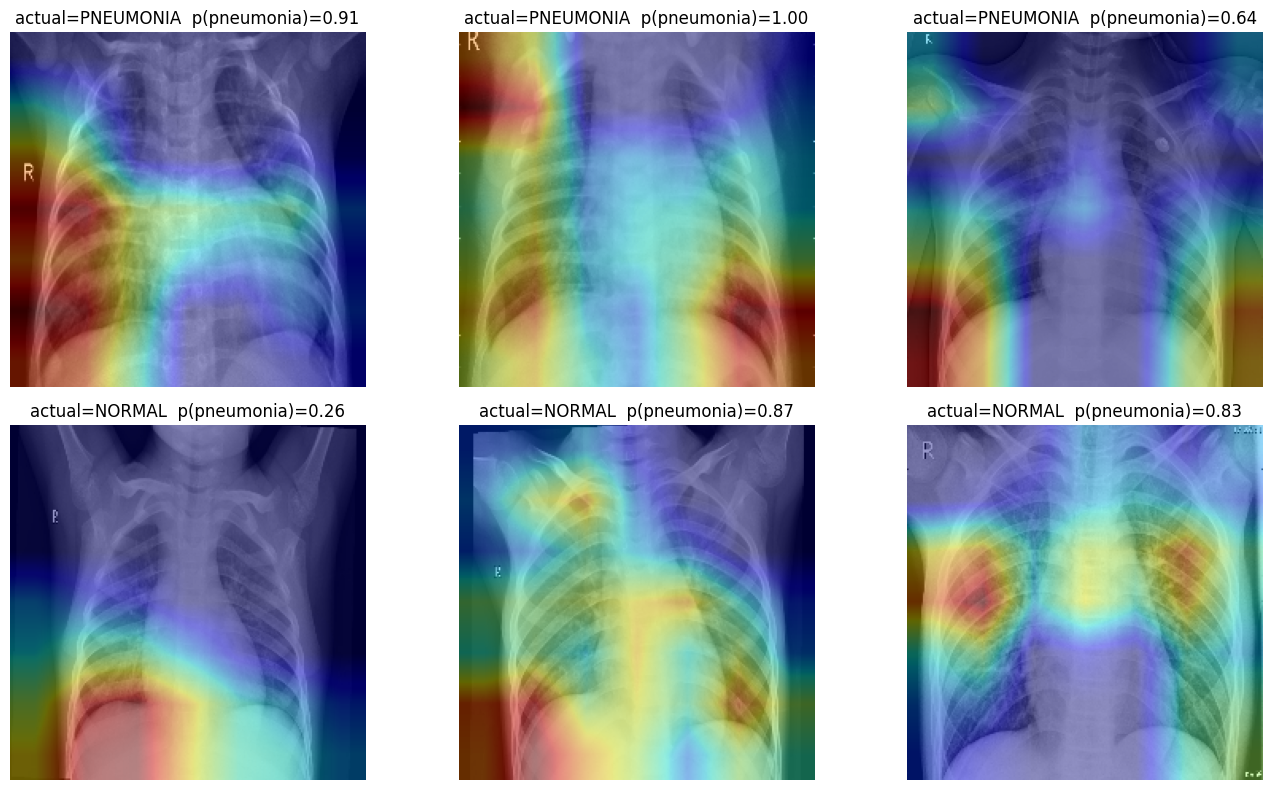

In [23]:
def grad_cam(model, img_array):
    # img_array: raw 0-255 image of shape (H, W, 3). Returns a 0-1 heatmap.
    base_model = model.get_layer('densenet121')
    # DenseNet121 (no top): the last layer is the 'relu' activation, so its output is the final feature map
    conv_model = keras.Model(base_model.input, base_model.get_layer('relu').output)
    head = keras.Sequential(model.layers[model.layers.index(base_model) + 1:])
    x = prep(img_array[None])
    with tf.GradientTape() as tape:
        conv_out = conv_model(x)
        tape.watch(conv_out)
        score = head(conv_out)[:, 0]          # head is computed from conv_out, so gradients reach it
    grads = tape.gradient(score, conv_out)
    weights_ = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv_out[0] * weights_, axis=-1)).numpy()
    return cam / (cam.max() + 1e-8)

def show_cam(path, true_label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE)).numpy()
    cam = tf.image.resize(grad_cam(model, img)[..., None], (IMG_SIZE, IMG_SIZE)).numpy()[..., 0]
    prob = float(model.predict(img[None], verbose=0)[0, 0])
    plt.imshow(img.astype('uint8')); plt.imshow(cam, cmap='jet', alpha=0.4)
    plt.title(f"actual={'PNEUMONIA' if true_label else 'NORMAL'}  p(pneumonia)={prob:.2f}")
    plt.axis('off')

samples = pd.concat([df_test[df_test.label == 1].sample(3, random_state=1),
                     df_test[df_test.label == 0].sample(3, random_state=1)])
plt.figure(figsize=(14, 8))
for i, (_, r) in enumerate(samples.iterrows()):
    plt.subplot(2, 3, i + 1); show_cam(r.path, r.label)
plt.tight_layout(); plt.show()

## 11. Error analysis
Look at the cases the model gets wrong before deciding how to improve it.

105 wrong of 624  |  false negatives: 7  false positives: 98


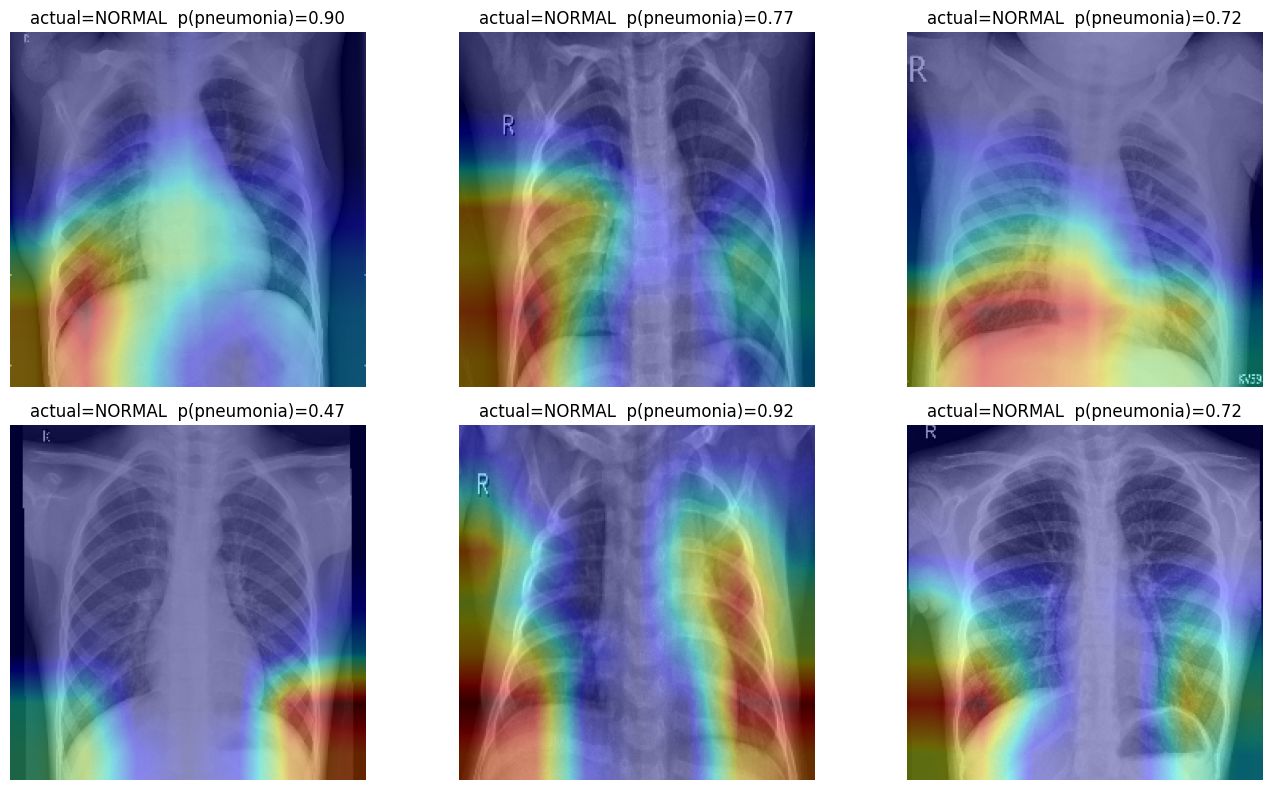

In [24]:
wrong = df_test.assign(prob=test_prob, pred=pred)[pred != test_true]
print(f'{len(wrong)} wrong of {len(df_test)}  |  false negatives: {((wrong.label==1)).sum()}  false positives: {((wrong.label==0)).sum()}')
plt.figure(figsize=(14, 8))
for i, (_, r) in enumerate(wrong.sample(min(6, len(wrong)), random_state=1).iterrows()):
    plt.subplot(2, 3, i + 1); show_cam(r.path, r.label)
plt.tight_layout(); plt.show()

## 12. Save the model and threshold for the Streamlit app

In [25]:
model.save('pneumonia_densenet121.keras')
with open('threshold.txt', 'w') as f:
    f.write(str(THRESHOLD))
print('saved. Download pneumonia_densenet121.keras and threshold.txt, place them next to app.py')

saved. Download pneumonia_densenet121.keras and threshold.txt, place them next to app.py


## 13. Experiment tracking with MLflow
MLflow records the parameters and metrics of each training run so experiments can be compared side by side. Runs are stored in your Drive (`mlruns/`) so they survive Colab restarts.

In [26]:
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'mlflow'], check=True)
import mlflow
import mlflow
from sklearn.metrics import f1_score, recall_score, precision_score, accuracy_score

os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
mlflow.set_tracking_uri('file:///content/drive/MyDrive/Pneumonia_Project/mlruns')
mlflow.set_experiment('pneumonia-xray')

def summarize(y_true, prob, t=0.5):
    p = (prob >= t).astype(int)
    return {'auc': roc_auc_score(y_true, prob),
            'recall': recall_score(y_true, p),
            'precision': precision_score(y_true, p),
            'f1': f1_score(y_true, p),
            'accuracy': accuracy_score(y_true, p)}

### 13a. Log the main run (DenseNet121, fine-tuned, class weights)

In [27]:
with mlflow.start_run(run_name='densenet121_finetuned_classweights'):
    mlflow.log_params({'model': 'DenseNet121', 'img_size': IMG_SIZE, 'batch': BATCH,
                       'lr_head': 1e-3, 'lr_finetune': 1e-5, 'unfrozen_layers': 40,
                       'class_weights': True, 'augmentation': 'flip/rotate/zoom/contrast',
                       'threshold': round(THRESHOLD, 4)})
    mlflow.log_metric('best_val_auc', max(hist['val_auc']))
    mlflow.log_metrics({f'test_{k}': v for k, v in summarize(test_true, test_prob, 0.5).items()})
    mlflow.log_metrics({f'test_{k}_tuned': v for k, v in summarize(test_true, test_prob, THRESHOLD).items()})
    fig, ax = plt.subplots(figsize=(4, 3.5))
    sns.heatmap(confusion_matrix(test_true, (test_prob >= THRESHOLD).astype(int)), annot=True, fmt='d',
                cmap='Blues', xticklabels=names, yticklabels=names, ax=ax)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    mlflow.log_figure(fig, 'confusion_matrix.png'); plt.close(fig)
    mlflow.log_artifact('pneumonia_densenet121.keras')
print('main run logged')

main run logged


### 13b. Comparison runs (optional, about 15-25 min on a T4)
Three simpler variants are trained and logged so the choice of DenseNet121 + class weights is backed by evidence. Set `RUN_VARIANTS = False` to skip.

In [28]:
def build_baseline_cnn():
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.RandomFlip('horizontal')(inputs)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.1)(x)
    x = layers.Rescaling(1.0 / 255)(x)
    for f in (32, 64, 128):
        x = layers.Conv2D(f, 3, padding='same', activation='relu')(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPool2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    return keras.Model(inputs, layers.Dense(1, activation='sigmoid')(x))

def train_variant(run_name, build_fn, use_class_weight, epochs=6, lr=1e-3):
    m = build_fn()
    m.compile(optimizer=keras.optimizers.Adam(lr), loss='binary_crossentropy',
              metrics=[keras.metrics.AUC(name='auc')])
    es = keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=3,
                                       restore_best_weights=True)
    h = m.fit(train_ds, validation_data=val_ds, epochs=epochs, verbose=2, callbacks=[es],
              class_weight=class_weight if use_class_weight else None)
    prob = m.predict(test_ds, verbose=0).ravel()
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params({'model': run_name, 'img_size': IMG_SIZE, 'batch': BATCH, 'lr': lr,
                           'class_weights': use_class_weight, 'epochs_max': epochs})
        mlflow.log_metric('best_val_auc', max(h.history['val_auc']))
        mlflow.log_metrics({f'test_{k}': v for k, v in summarize(test_true, prob).items()})
    return prob

RUN_VARIANTS = True
if RUN_VARIANTS:
    train_variant('baseline_cnn_scratch', build_baseline_cnn, use_class_weight=False, epochs=10)
    train_variant('densenet121_frozen_no_classweights', lambda: build_model()[0], use_class_weight=False)
    train_variant('densenet121_frozen_classweights', lambda: build_model()[0], use_class_weight=True)

Epoch 1/10
139/139 - 45s - 321ms/step - auc: 0.8898 - loss: 0.3725 - val_auc: 0.4737 - val_loss: 0.6013
Epoch 2/10
139/139 - 84s - 602ms/step - auc: 0.9306 - loss: 0.2959 - val_auc: 0.4793 - val_loss: 2.0416
Epoch 3/10
139/139 - 39s - 283ms/step - auc: 0.9438 - loss: 0.2641 - val_auc: 0.4716 - val_loss: 2.5017
Epoch 4/10
139/139 - 38s - 275ms/step - auc: 0.9487 - loss: 0.2538 - val_auc: 0.7268 - val_loss: 1.0916
Epoch 5/10
139/139 - 41s - 298ms/step - auc: 0.9558 - loss: 0.2364 - val_auc: 0.5016 - val_loss: 2.8863
Epoch 6/10
139/139 - 41s - 294ms/step - auc: 0.9553 - loss: 0.2365 - val_auc: 0.7399 - val_loss: 3.7125
Epoch 7/10
139/139 - 41s - 296ms/step - auc: 0.9619 - loss: 0.2195 - val_auc: 0.5890 - val_loss: 5.7810
Epoch 8/10
139/139 - 44s - 319ms/step - auc: 0.9660 - loss: 0.2058 - val_auc: 0.7401 - val_loss: 1.1185
Epoch 9/10
139/139 - 40s - 284ms/step - auc: 0.9679 - loss: 0.2013 - val_auc: 0.5000 - val_loss: 7.0373
Epoch 10/10
139/139 - 41s - 295ms/step - auc: 0.9714 - loss: 0.1

### 13c. Compare all runs

In [29]:
runs = mlflow.search_runs(experiment_names=['pneumonia-xray'])
cols = ['tags.mlflow.runName', 'metrics.test_auc', 'metrics.test_recall',
        'metrics.test_precision', 'metrics.test_f1', 'metrics.best_val_auc']
table = runs[cols].sort_values('metrics.test_auc', ascending=False)
table.columns = ['run', 'test_auc', 'test_recall', 'test_precision', 'test_f1', 'best_val_auc']
display(table.round(3).reset_index(drop=True))

,run,test_auc,test_recall,test_precision,test_f1,best_val_auc
0,densenet121_finetuned_classweights,0.960,0.969,0.848,0.904,0.994
1,densenet121_finetuned_classweights,0.959,0.964,0.858,0.908,0.993
2,densenet121_frozen_classweights,0.948,0.936,0.871,0.902,0.986
3,densenet121_frozen_no_classweights,0.948,0.969,0.786,0.868,0.986
4,baseline_cnn_scratch,0.884,0.656,0.928,0.769,0.974
5,baseline_cnn_scratch,0.746,1.000,0.625,0.769,0.740


**To view the MLflow dashboard:** download the `mlruns` folder from your Drive, then run `mlflow ui` in the folder that contains it and open http://127.0.0.1:5000. Select the runs and click **Compare**, then screenshot the comparison for your README.

## Notes for the README / interviews
- Dataset: Kaggle *Chest X-Ray Images (Pneumonia)*. It is imbalanced (about 3x more pneumonia than normal images), and the official test set is distributed differently from the training set.
- Report **recall, precision and ROC-AUC**, not accuracy alone.
- Limitations: a single public dataset, no external validation, images from one source; this is a screening demo, not a diagnostic tool.
- Next steps: test on a second independent chest X-ray dataset, try EfficientNet, calibrate probabilities.